In [1]:
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

base = "/content/drive/MyDrive/volatility-risk-analysis"
ticker = "GLD"

returns = pd.read_csv(f"{base}/data/{ticker}_returns.csv",
                      index_col=0, parse_dates=True).squeeze("columns")

print(returns.shape)
print(returns.head())

Mounted at /content/drive
(5481,)
Date
2005-01-04   -0.006530
2005-01-05   -0.001639
2005-01-06   -0.012261
2005-01-07   -0.007382
2005-01-10    0.002626
Name: GLD, dtype: float64


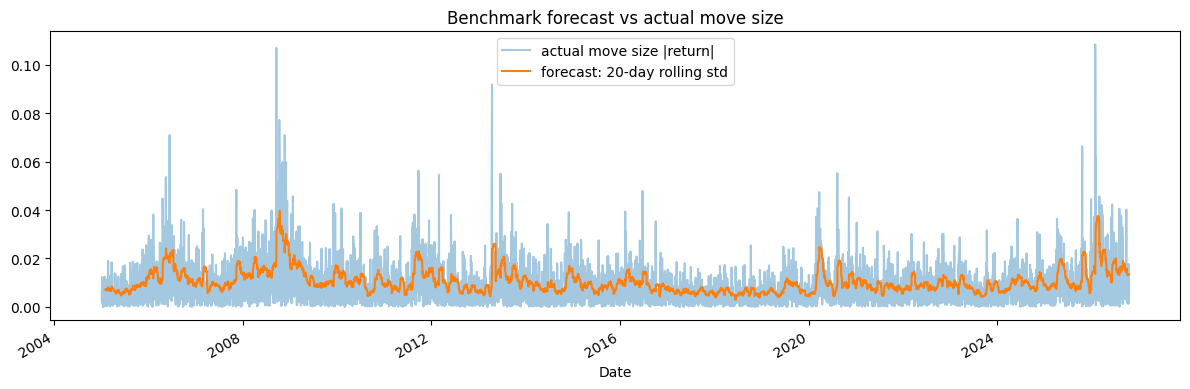

Date
2005-02-02    0.007031
2005-02-03    0.006931
2005-02-04    0.007337
2005-02-07    0.006930
2005-02-08    0.006825
Name: GLD, dtype: float64


In [2]:
# "Actual" move size each day: the return with its sign removed
actual_size = returns.abs()

# Benchmark forecast: the typical size of moves over the last 20 trading days
# (std = standard deviation = typical size of a move)
roll_vol = returns.rolling(20).std().shift(1)

# Plot them together
fig, ax = plt.subplots(figsize=(12, 4))
actual_size.plot(ax=ax, alpha=0.4, label="actual move size |return|")
roll_vol.plot(ax=ax, label="forecast: 20-day rolling std")
ax.legend()
ax.set_title("Benchmark forecast vs actual move size")
plt.tight_layout()
plt.savefig(f"{base}/outputs/baseline_{ticker}.png")
plt.show()

print(roll_vol.dropna().head())

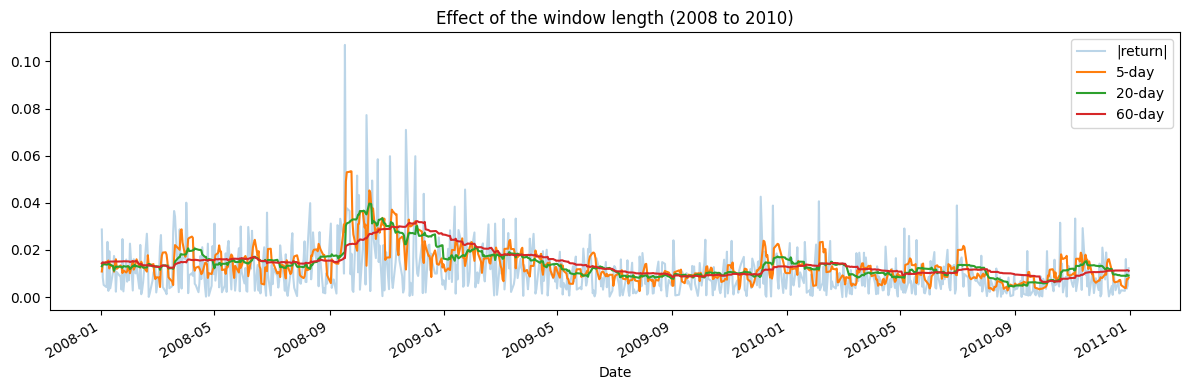

In [3]:
fig, ax = plt.subplots(figsize=(12, 4))
actual_size["2008":"2010"].plot(ax=ax, alpha=0.3, label="|return|")
for w in [5, 20, 60]:
    returns.rolling(w).std().shift(1)["2008":"2010"].plot(ax=ax, label=f"{w}-day")
ax.legend()
ax.set_title("Effect of the window length (2008 to 2010)")
plt.tight_layout()
plt.show()

In [4]:
from statsmodels.tsa.arima.model import ARIMA

arima_res = ARIMA(returns, order=(1, 0, 1)).fit()
print(arima_res.summary())

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


                               SARIMAX Results                                
Dep. Variable:                    GLD   No. Observations:                 5481
Model:                 ARIMA(1, 0, 1)   Log Likelihood               16680.284
Date:                Sun, 18 Oct 2026   AIC                         -33352.567
Time:                        12:49:24   BIC                         -33326.131
Sample:                             0   HQIC                        -33343.345
                               - 5481                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.000      2.576      0.010    9.51e-05       0.001
ar.L1          0.3622      0.468      0.774      0.439      -0.555       1.280
ma.L1         -0.3780      0.464     -0.814      0.4

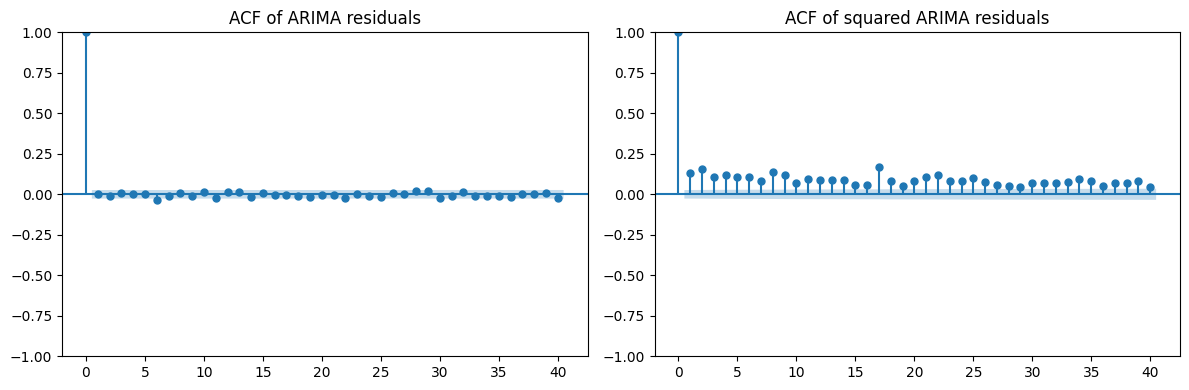

Ljung-Box on residuals:
      lb_stat  lb_pvalue
10  11.703646   0.305380
20  21.367392   0.375799

Ljung-Box on squared residuals:
        lb_stat      lb_pvalue
10   736.334516  9.901296e-152
20  1196.323705  4.568634e-241


In [5]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

resid = arima_res.resid

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(resid, lags=40, ax=ax[0], title="ACF of ARIMA residuals")
plot_acf(resid**2, lags=40, ax=ax[1], title="ACF of squared ARIMA residuals")
plt.tight_layout()
plt.savefig(f"{base}/outputs/arima_resid_{ticker}.png")
plt.show()

print("Ljung-Box on residuals:")
print(acorr_ljungbox(resid, lags=[10, 20], return_df=True))
print("\nLjung-Box on squared residuals:")
print(acorr_ljungbox(resid**2, lags=[10, 20], return_df=True))

In [6]:
from statsmodels.stats.diagnostic import het_arch

lm_stat, lm_p, f_stat, f_p = het_arch(resid, nlags=10)
print(f"ARCH-LM statistic = {lm_stat:.2f}, p-value = {lm_p:.3g}")

ARCH-LM statistic = 373.91, p-value = 3.33e-74


In [7]:
split = int(len(returns) * 0.8)
train, test = returns.iloc[:split], returns.iloc[split:]

fit_train = ARIMA(train, order=(1, 0, 1)).fit()
fit_all = fit_train.apply(returns)
arima_pred = fit_all.fittedvalues.loc[test.index]

def rmse(actual, forecast):
    return np.sqrt(np.mean((actual - forecast) ** 2))

print("Test period:", test.index[0].date(), "to", test.index[-1].date())
print("ARIMA RMSE:              ", rmse(test, arima_pred))
print("Zero forecast RMSE:      ", rmse(test, 0))
print("Yesterday's return RMSE: ", rmse(test, returns.shift(1).loc[test.index]))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


Test period: 2022-06-03 to 2026-10-16
ARIMA RMSE:               0.012362073278768086
Zero forecast RMSE:       0.012380957631404935
Yesterday's return RMSE:  0.01780714564931897


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g., forecasting.
  self._init_dates(dates, freq)


In [8]:
!pip install arch -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 982.9/982.9 kB 21.2 MB/s eta 0:00:00


In [9]:
from arch import arch_model

r = returns * 100          # work in percent, the optimiser behaves better

garch = arch_model(r, mean="Constant", vol="GARCH", p=1, q=1, dist="normal")
garch_res = garch.fit(disp="off")
print(garch_res.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                    GLD   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -7967.10
Distribution:                  Normal   AIC:                           15942.2
Method:            Maximum Likelihood   BIC:                           15968.6
                                        No. Observations:                 5481
Date:                Sun, Oct 18 2026   Df Residuals:                     5480
Time:                        13:04:38   Df Model:                            1
                                  Mean Model                                 
                 coef    std err          t      P>|t|       95.0% Conf. Int.
-----------------------------------------------------------------------------
mu             0.0251  1.326e-02      1.894  5.817e-02 

In [13]:
p = garch_res.params
omega, alpha, beta = p["omega"], p["alpha[1]"], p["beta[1]"]

today_risk = 1.2   # percent
shock = 8       # percent

tomorrow_var = omega + alpha * shock**2 + beta * today_risk**2
print("Tomorrow's risk forecast:", round(tomorrow_var**0.5, 3), "%")

Tomorrow's risk forecast: 2.282 %


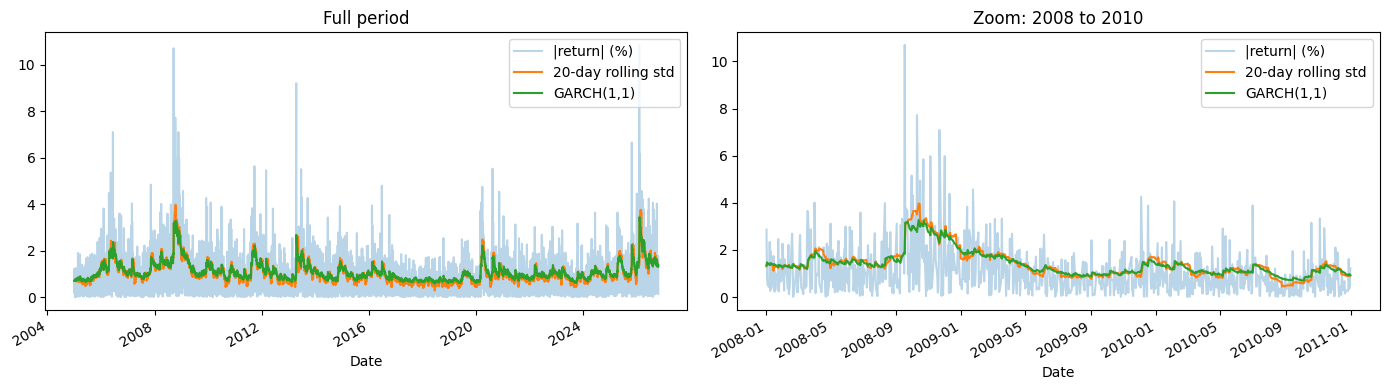

In [14]:
cond_vol = garch_res.conditional_volatility       # GARCH risk estimate, in percent
bench = returns.rolling(20).std().shift(1) * 100  # 20-day benchmark, in percent
size = returns.abs() * 100                        # actual move size, in percent

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

for a, sl in zip(ax, [slice(None), slice("2008", "2010")]):
    size.loc[sl].plot(ax=a, alpha=0.3, label="|return| (%)")
    bench.loc[sl].plot(ax=a, label="20-day rolling std")
    cond_vol.loc[sl].plot(ax=a, label="GARCH(1,1)")
    a.legend()

ax[0].set_title("Full period")
ax[1].set_title("Zoom: 2008 to 2010")
plt.tight_layout()
plt.savefig(f"{base}/outputs/garch_vs_baseline_{ticker}.png")
plt.show()

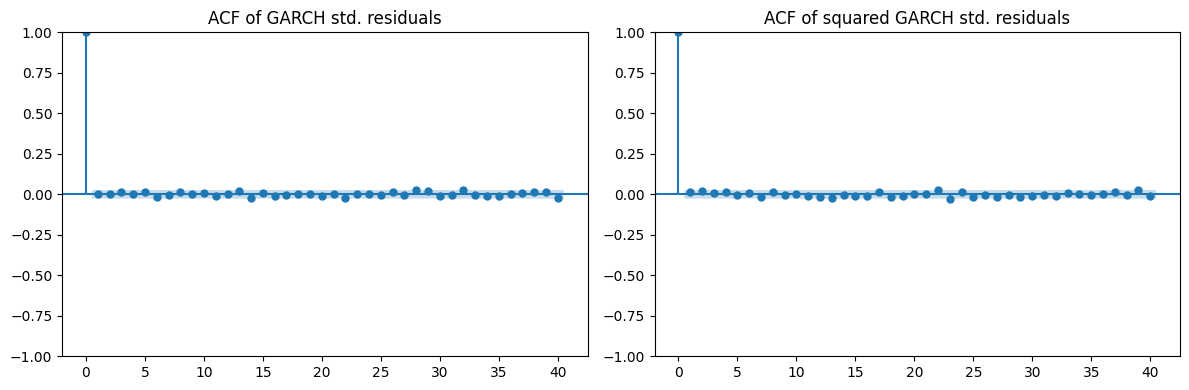

Ljung-Box on squared standardized residuals:
      lb_stat  lb_pvalue
10   7.451076   0.682284
20  16.118694   0.709234

ARCH-LM statistic = 7.29, p-value = 0.698
Excess kurtosis of std. residuals: 2.4


In [15]:
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

std_resid = garch_res.std_resid.dropna()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
plot_acf(std_resid, lags=40, ax=ax[0], title="ACF of GARCH std. residuals")
plot_acf(std_resid**2, lags=40, ax=ax[1], title="ACF of squared GARCH std. residuals")
plt.tight_layout()
plt.savefig(f"{base}/outputs/garch_resid_{ticker}.png")
plt.show()

print("Ljung-Box on squared standardized residuals:")
print(acorr_ljungbox(std_resid**2, lags=[10, 20], return_df=True))

lm_stat, lm_p, _, _ = het_arch(std_resid, nlags=10)
print(f"\nARCH-LM statistic = {lm_stat:.2f}, p-value = {lm_p:.3g}")
print("Excess kurtosis of std. residuals:", round(std_resid.kurt(), 2))

In [16]:
models = {
    "GARCH normal": arch_model(r, mean="Constant", vol="GARCH", p=1, q=1, dist="normal"),
    "GARCH t":      arch_model(r, mean="Constant", vol="GARCH", p=1, q=1, dist="t"),
    "GJR-GARCH t":  arch_model(r, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t"),
}
fits = {name: m.fit(disp="off") for name, m in models.items()}

comp = pd.DataFrame({
    name: {"AIC": f.aic, "BIC": f.bic, "log-lik": f.loglikelihood}
    for name, f in fits.items()
}).T
print(comp.round(1))

print("\nGARCH t parameters:")
print(fits["GARCH t"].params.round(4))

print("\nGJR-GARCH t parameters and p-values:")
print(pd.DataFrame({
    "coef": fits["GJR-GARCH t"].params,
    "p-value": fits["GJR-GARCH t"].pvalues,
}).round(4))

                  AIC      BIC  log-lik
GARCH normal  15942.2  15968.6  -7967.1
GARCH t       15585.0  15618.1  -7787.5
GJR-GARCH t   15564.2  15603.8  -7776.1

GARCH t parameters:
mu          0.0473
omega       0.0090
alpha[1]    0.0465
beta[1]     0.9480
nu          5.3535
Name: params, dtype: float64

GJR-GARCH t parameters and p-values:
            coef  p-value
mu        0.0537   0.0000
omega     0.0081   0.0005
alpha[1]  0.0660   0.0000
gamma[1] -0.0392   0.0000
beta[1]   0.9503   0.0000
nu        5.3896   0.0000


In [17]:
best = fits["GJR-GARCH t"]
p = best.params
omega, alpha, gamma, beta = p["omega"], p["alpha[1]"], p["gamma[1]"], p["beta[1]"]

today_var = 1.2 ** 2     # today's risk level of 1.2% per day
shock = 3.0              # a 3% move

up   = omega + alpha * shock**2 + beta * today_var
down = omega + (alpha + gamma) * shock**2 + beta * today_var
print(f"After a +3% day: tomorrow's risk forecast = {up**0.5:.3f}%")
print(f"After a -3% day: tomorrow's risk forecast = {down**0.5:.3f}%")

sr = best.std_resid.dropna()
lm_stat, lm_p, _, _ = het_arch(sr, nlags=10)
print(f"\nARCH-LM on GJR-t std. residuals: statistic = {lm_stat:.2f}, p-value = {lm_p:.3f}")

After a +3% day: tomorrow's risk forecast = 1.404%
After a -3% day: tomorrow's risk forecast = 1.272%

ARCH-LM on GJR-t std. residuals: statistic = 31.72, p-value = 0.000


              ARCH-LM stat  ARCH-LM p  ARCH-LM stat (clipped)  \
GARCH normal        7.2876     0.6980                  8.2797   
GARCH t            18.7121     0.0441                 13.5480   
GJR-GARCH t        31.7156     0.0004                 12.1969   

              ARCH-LM p (clipped)  LB p (lag 10)  LB p (lag 20)  
GARCH normal               0.6015         0.6823         0.7092  
GARCH t                    0.1946         0.0273         0.1305  
GJR-GARCH t                0.2721         0.0002         0.0025  


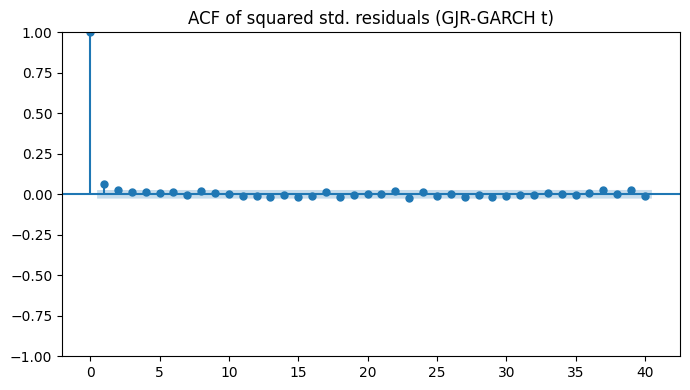

In [18]:
rows = {}
for name, f in fits.items():
    sr = f.std_resid.dropna()
    lm_stat, lm_p, _, _ = het_arch(sr, nlags=10)
    lm_stat_c, lm_p_c, _, _ = het_arch(sr.clip(-4, 4), nlags=10)
    lb = acorr_ljungbox(sr**2, lags=[10, 20], return_df=True)
    rows[name] = {
        "ARCH-LM stat": lm_stat,
        "ARCH-LM p": lm_p,
        "ARCH-LM stat (clipped)": lm_stat_c,
        "ARCH-LM p (clipped)": lm_p_c,
        "LB p (lag 10)": lb["lb_pvalue"].iloc[0],
        "LB p (lag 20)": lb["lb_pvalue"].iloc[1],
    }
print(pd.DataFrame(rows).T.round(4))

sr = fits["GJR-GARCH t"].std_resid.dropna()
fig, ax = plt.subplots(figsize=(7, 4))
plot_acf(sr**2, lags=40, ax=ax, title="ACF of squared std. residuals (GJR-GARCH t)")
plt.tight_layout()
plt.show()

In [19]:
init = 750      # first 750 days are only used for the first fit
step = 20       # refit every 20 trading days

model_defs = {
    "GARCH normal": dict(vol="GARCH", p=1, o=0, q=1, dist="normal"),
    "GARCH t":      dict(vol="GARCH", p=1, o=0, q=1, dist="t"),
    "GJR-GARCH t":  dict(vol="GARCH", p=1, o=1, q=1, dist="t"),
}

forecasts = {name: [] for name in model_defs}
starts = list(range(init, len(r), step))

for i, start in enumerate(starts):
    if i % 40 == 0:
        print("refit", i, "of", len(starts))
    end = min(start + step, len(r))
    for name, spec in model_defs.items():
        fit = arch_model(r.iloc[:start], mean="Constant", **spec).fit(disp="off")
        fixed = arch_model(r.iloc[:end], mean="Constant", **spec).fix(fit.params.values)
        forecasts[name].append(fixed.conditional_volatility.iloc[start:end])

vol_fc = pd.DataFrame({name: pd.concat(parts) for name, parts in forecasts.items()})
vol_fc["20-day rolling std"] = bench.loc[vol_fc.index]

vol_fc.to_csv(f"{base}/data/{ticker}_vol_forecasts.csv")
print(vol_fc.shape)
print("Test period:", vol_fc.index[0].date(), "to", vol_fc.index[-1].date())
print(vol_fc.head())
print("missing:", vol_fc.isna().sum().sum())

refit 0 of 237
refit 40 of 237
refit 80 of 237
refit 120 of 237
refit 160 of 237
refit 200 of 237
(4731, 4)
Test period: 2007-12-27 to 2026-10-16
            GARCH normal   GARCH t  GJR-GARCH t  20-day rolling std
Date                                                               
2007-12-27      1.441052  1.427380     1.453054            1.368149
2007-12-28      1.409996  1.398374     1.430457            1.356772
2007-12-31      1.424427  1.410382     1.472267            1.336893
2008-01-02      1.401563  1.389816     1.449314            1.307964
2008-01-03      1.492073  1.472461     1.598145            1.414715
missing: 0


In [20]:
actual_var = r.loc[vol_fc.index] ** 2     # squared return = stand-in for actual variance
fc_var = vol_fc ** 2                      # forecasts converted from volatility to variance

scores = pd.DataFrame({
    "QLIKE": fc_var.apply(lambda h: (np.log(h) + actual_var / h).mean()),
    "RMSE (variance)": fc_var.apply(lambda h: np.sqrt(((actual_var - h) ** 2).mean())),
})
scores["QLIKE gain vs rolling"] = scores.loc["20-day rolling std", "QLIKE"] - scores["QLIKE"]
print(scores.round(4))
print("\nBest by QLIKE:", scores["QLIKE"].idxmin())
print("Best by RMSE: ", scores["RMSE (variance)"].idxmin())

                     QLIKE  RMSE (variance)  QLIKE gain vs rolling
GARCH normal        1.0604           3.8469                 0.0886
GARCH t             1.0618           3.8490                 0.0873
GJR-GARCH t         1.0665           3.8475                 0.0825
20-day rolling std  1.1490           3.9191                 0.0000

Best by QLIKE: GARCH normal
Best by RMSE:  GARCH normal


QLIKE gain vs rolling benchmark (positive = model better):
                  GARCH normal  GARCH t  GJR-GARCH t  days
2008-2009 crisis        0.0391   0.0382      -0.0084   508
2010-2013               0.1059   0.1066       0.0828  1006
2014-2019 calm          0.0704   0.0745       0.0747  1510
2020-2021               0.1144   0.1056       0.1143   505
2022-2026               0.1071   0.1002       0.1172  1202


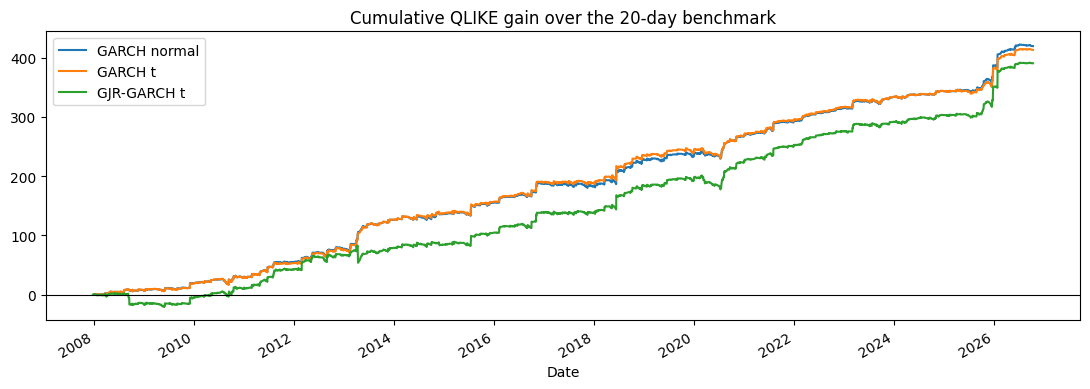

In [21]:
periods = {
    "2008-2009 crisis": ("2007-12-27", "2009-12-31"),
    "2010-2013":        ("2010-01-01", "2013-12-31"),
    "2014-2019 calm":   ("2014-01-01", "2019-12-31"),
    "2020-2021":        ("2020-01-01", "2021-12-31"),
    "2022-2026":        ("2022-01-01", "2026-12-31"),
}

# daily QLIKE loss for every model
daily = np.log(fc_var) + (1 / fc_var).mul(actual_var, axis=0)

by_period = pd.DataFrame({name: daily.loc[a:b].mean() for name, (a, b) in periods.items()}).T
gain = -by_period.sub(by_period["20-day rolling std"], axis=0).drop(columns="20-day rolling std")
gain["days"] = [len(daily.loc[a:b]) for a, b in periods.values()]
print("QLIKE gain vs rolling benchmark (positive = model better):")
print(gain.round(4))

# running total of the gain over time
fig, ax = plt.subplots(figsize=(11, 4))
for name in ["GARCH normal", "GARCH t", "GJR-GARCH t"]:
    (daily["20-day rolling std"] - daily[name]).cumsum().plot(ax=ax, label=name)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Cumulative QLIKE gain over the 20-day benchmark")
ax.legend()
plt.tight_layout()
plt.savefig(f"{base}/outputs/cumulative_gain_{ticker}.png")
plt.show()